<a href="https://colab.research.google.com/github/jyotimaharishi/Resume--Screening---app/blob/main/resume_screening_with_python_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

resume screening app by  using python  or python tools

1.   it uses python language
2.  it also uses python lib such as
3.  nlp, dl, ml, pandas, numpy and data visualization , eda



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import os

file_path = '/content/label_encoder.pkl'
if os.path.exists(file_path):
    print("File size (bytes):", os.path.getsize(file_path))
    with open(file_path, 'rb') as f:
        print("First 100 bytes:", f.read(100))
else:
    print("File does not exist at this path.")

File size (bytes): 0
First 100 bytes: b''


In [4]:
!pip install kagglehub

import kagglehub

# Automatically downloads and extracts the dataset straight from Kaggle
path = kagglehub.dataset_download("snehaanbhawal/resume-dataset")

print("Dataset successfully downloaded to folder:", path)

100%|██████████| 62.5M/62.5M [00:00<00:00, 86.0MB/s]

Extracting files...


Dataset successfully downloaded to folder: /root/.cache/kagglehub/datasets/snehaanbhawal/resume-dataset/versions/1


In [ ]:
import pandas as pd

# Load the dataset CSV file
df = pd.read_csv('/kaggle/input/resume-dataset/Resume/Resume.csv')

print("Dataset loaded successfully! Shape:", df.shape)
df.head()

Dataset loaded successfully! Shape: (2484, 4)


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [ ]:
df.shape

(2484, 4)

Explloring **Categories** **bold text**

In [ ]:
df['Category'].value_counts()

,count
Category,
INFORMATION-TECHNOLOGY,120
BUSINESS-DEVELOPMENT,120
ADVOCATE,118
CHEF,118
ENGINEERING,118
ACCOUNTANT,118
FINANCE,118
FITNESS,117
AVIATION,117


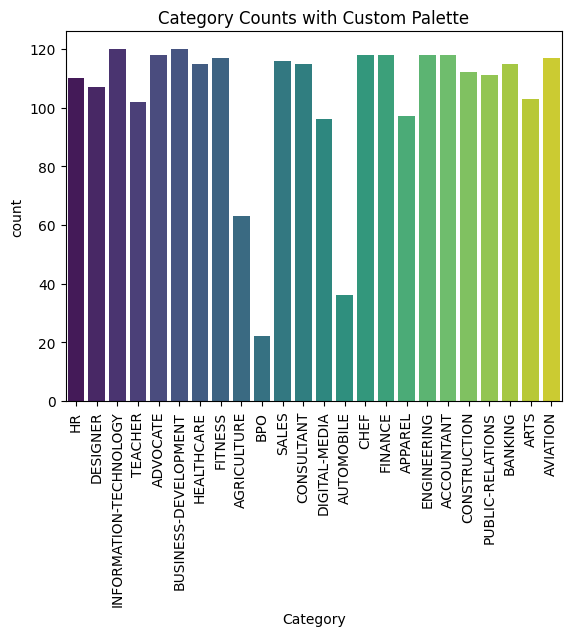

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Using hue to give each bar a distinct color palette
sns.countplot(data=df, x='Category', hue='Category', palette='viridis', legend=False)
plt.title('Category Counts with Custom Palette')
plt.xticks(rotation=90)
plt.show()

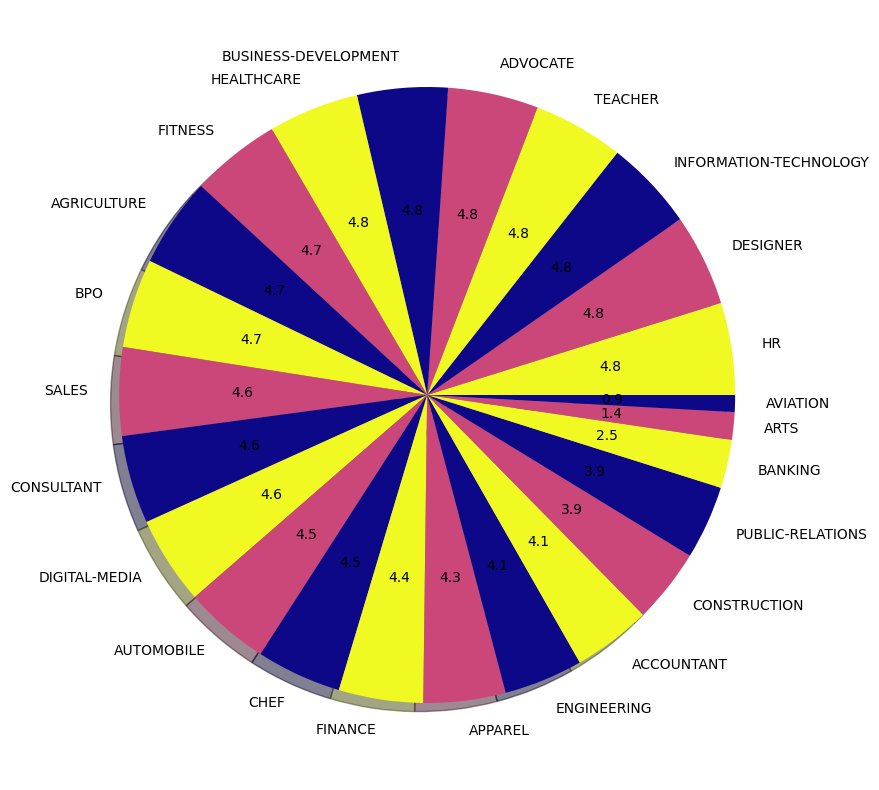

In [ ]:
from numpy._core.defchararray import count
Counts=df['Category'].value_counts()
labels=df['Category'].unique()
plt.figure(figsize=(15,10))
plt.pie(Counts,labels=labels,autopct='%1.1f',shadow=True,colors=plt.cm.plasma_r(np.linspace(0,1,3)))
plt.show()


EXPLORING RESUME

In [ ]:
df['Category'][0]

'HR'

In [ ]:
# To get the first resume string:
df['Resume_str'][0]

# Or if you want the HTML version:
df['Resume_html'][0]

'<div class="fontsize fontface vmargins hmargins linespacing pagesize" id="document"> <div class="section firstsection" id="SECTION_NAME500375979" style="\n      padding-top:0px;\n    "> <div class="paragraph PARAGRAPH_NAME firstparagraph" id="PARAGRAPH_500375979_1_326506904" style="\n      padding-top:0px;\n    "> <div class="name" itemprop="name"> <span class="field fName" id="500375979FNAM1"> </span> <span> </span> <span class="field" id="500375979LNAM1"> HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR</span> </div> </div> </div> <div class="section" id="SECTION_SUMM500375981" style="\n      padding-top:0px;\n    "> <div class="heading bottomborder"> <div class="sectiontitle" id="SECTNAME_SUMM500375981"> Summary</div> </div> <div class="paragraph firstparagraph" id="PARAGRAPH_500375981_1_326506917" style="\n      padding-top:0px;\n    "> <div class="field singlecolumn" id="500375981FRFM1"> <p align="LEFT"> Dedicated Customer Service Manager with 15+ years of experience in H

cleaning data:
urls
hastags
punctuations
mentions
special letter

In [ ]:
import re


def cleanResume(txt):
  # Remove URLs
  cleanTxt = re.sub(r'http\S+\s*', ' ', txt)
  # Remove RT and cc
  cleanTxt = re.sub(r'\b(RT|cc)\b', ' ', cleanTxt)
  # Remove hashtags
  cleanTxt = re.sub(r'#\S+', ' ', cleanTxt)
  # Remove mentions (@usernames)
  cleanTxt = re.sub(r'@\S+', ' ', cleanTxt)
  # Remove punctuation and special characters
  cleanTxt = re.sub(
      r'[%s]' % re.escape("""!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~"""), ' ', cleanTxt
  )
  # Remove non-ASCII characters
  cleanTxt = re.sub(r'[^\x00-\x7f]', ' ', cleanTxt)
  # Replace multiple spaces/newlines with a single space
  cleanTxt = re.sub(r'\s+', ' ', cleanTxt).strip()

  return cleanTxt

<>:15: SyntaxWarning: invalid escape sequence '\]'
<>:15: SyntaxWarning: invalid escape sequence '\]'
/tmp/ipykernel_2030/3394281167.py:15: SyntaxWarning: invalid escape sequence '\]'
  r'[%s]' % re.escape("""!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~"""), ' ', cleanTxt


In [ ]:
cleanResume("my ####website like this http://helloworld and acess @@@it")

'my like this and acess'

In [ ]:
df['Resume_str']=df['Resume_str'].apply(lambda x: cleanResume(x))

In [ ]:
df['Resume_str'][0]

'HR ADMINISTRATOR MARKETING ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15 years of experience in Hospitality and Customer Service Management Respected builder and leader of customer focused teams strives to instill a shared enthusiastic commitment to customer service Highlights Focused on customer satisfaction Team management Marketing savvy Conflict resolution techniques Training and development Skilled multi tasker Client relations specialist Accomplishments Missouri DOT Supervisor Training Certification Certified by IHG in Customer Loyalty and Marketing by Segment Hilton Worldwide General Manager Training Certification Accomplished Trainer for cross server hospitality systems such as Hilton OnQ Micros Opera PMS Fidelio OPERA Reservation System ORS Holidex Completed courses and seminars in customer service sales strategies inventory control loss prevention safety time management leadership and performance assessment Experience HR Administrator Marketin

words into categorical columns


In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [11]:
from sklearn.preprocessing import LabelEncoder

# 1. Initialize LabelEncoder
le = LabelEncoder()

# 2. Fit and transform the column (you can do both in one line with fit_transform)
df['category'] = le.fit_transform(df['Category'])

# Check the mapping
df[['Category', 'category']].head()

NameError: name 'df' is not defined

In [ ]:
df.category.unique()

array([19, 13, 20, 23,  1,  9, 18, 17,  2,  8, 22, 12, 14,  5, 10, 16,  3,
       15,  0, 11, 21,  7,  4,  6])

In [ ]:
# 'HR ADMINISTRATOR MARKETING ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15 years of experience in Hospitality and Customer Service Management Respected builder and leader of customer focused teams strives to instill a shared enthusiastic commitment to customer service Highlights Focused on customer satisfaction Team management Marketing savvy Conflict resolution techniques Training and development Skilled multi tasker Client relations specialist Accomplishments Missouri DOT Supervisor Training Certification Certified by IHG in Customer
#Loyalty and Marketing by Segment Hilton Worldwide General Manager Training Certification Accomplished Trainer for cross server hospitality systems such as
#Hilton OnQ Micros Opera PMS Fidelio OPERA Reservation System ORS Holidex Completed courses and seminars in customer service sales strategies inventory control loss prevention
#safety time management leadership and performance assessment Experience HR Administrator Marketing…<'

# **vectorizations**

In [ ]:
df['Resume_str'][0]

'HR ADMINISTRATOR MARKETING ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15 years of experience in Hospitality and Customer Service Management Respected builder and leader of customer focused teams strives to instill a shared enthusiastic commitment to customer service Highlights Focused on customer satisfaction Team management Marketing savvy Conflict resolution techniques Training and development Skilled multi tasker Client relations specialist Accomplishments Missouri DOT Supervisor Training Certification Certified by IHG in Customer Loyalty and Marketing by Segment Hilton Worldwide General Manager Training Certification Accomplished Trainer for cross server hospitality systems such as Hilton OnQ Micros Opera PMS Fidelio OPERA Reservation System ORS Holidex Completed courses and seminars in customer service sales strategies inventory control loss prevention safety time management leadership and performance assessment Experience HR Administrator Marketin

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize vectorizer
tfidf = TfidfVectorizer(stop_words='english')

# Use fit_transform with the correctly capitalized column name
RequiredText = tfidf.fit_transform(
    df['cleaned_resume'] if 'cleaned_resume' in df else df['Resume_str']
)

print("Vectorization complete! Matrix shape:", RequiredText.shape)

Vectorization complete! Matrix shape: (2484, 40009)


In [ ]:
df

,ID,Resume_str,Resume_html,Category,category,cleaned_resume
0,16852973,HR ADMINISTRATOR MARKETING ASSOCIATE HR ADMINI...,"<div class=""fontsize fontface vmargins hmargin...",HR,19,HR ADMINISTRATOR MARKETING ASSOCIATE HR ADMINI...
1,22323967,HR SPECIALIST US HR OPERATIONS Summary Versati...,"<div class=""fontsize fontface vmargins hmargin...",HR,19,HR SPECIALIST US HR OPERATIONS Summary Versati...
2,33176873,HR DIRECTOR Summary Over 20 years experience i...,"<div class=""fontsize fontface vmargins hmargin...",HR,19,HR DIRECTOR Summary Over 20 years experience i...
3,27018550,HR SPECIALIST Summary Dedicated Driven and Dyn...,"<div class=""fontsize fontface vmargins hmargin...",HR,19,HR SPECIALIST Summary Dedicated Driven and Dyn...
4,17812897,HR MANAGER Skill Highlights HR SKILLS HR Depar...,"<div class=""fontsize fontface vmargins hmargin...",HR,19,HR MANAGER Skill Highlights HR SKILLS HR Depar...
...,...,...,...,...,...,...
2479,99416532,RANK SGT E 5 NON COMMISSIONED OFFICER IN CHARG...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION,6,RANK SGT E 5 NON COMMISSIONED OFFICER IN CHARG...
2480,24589765,GOVERNMENT RELATIONS COMMUNICATIONS AND ORGANI...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION,6,GOVERNMENT RELATIONS COMMUNICATIONS AND ORGANI...
2481,31605080,GEEK SQUAD AGENT Professional Profile IT suppo...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION,6,GEEK SQUAD AGENT Professional Profile IT suppo...
2482,21190805,PROGRAM DIRECTOR OFFICE MANAGER Summary Highly...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION,6,PROGRAM DIRECTOR OFFICE MANAGER Summary Highly...


In [ ]:
from sklearn. model_selection import train_test_split


In [ ]:
x_train,x_test,y_train, y_test=train_test_split(RequiredText,df['category'],test_size=0.2, random_state=42)

In [ ]:
x_train.shape

(1987, 40009)

In [ ]:
x_test.shape

(497, 40009)

now let's train the model and print the classification report

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier()
clf.fit(x_train, y_train)

# Fix typo: use .predict() instead of .predit()
ypred = clf.predict(x_test)
print(ypred)

[23 14 11 10  7  9 13  9 23 13 11  1  1  8  1 18  9  1  1  9  3 19 13  7
 14  9 13  9 12 19  5 18  0  9  4 12 18 10 15 17  9 12 13 12 19  0  4 11
 10  9  6 12 10 18 22  9  9  1  3 21  9 10 12  5  4  9  0 23 18 11  7  9
 21 22  6  6  9 16 22 20 23  0 10  6  9  6 18 23 21 11 15  0 20 19 22 18
  0 23  0  0  7  3 23 14  1  1 14 18  5  5 15 23  1 22  7 16 21 11 14 11
 14  7 18  8 18  0  0  4  1  9  1  1  2 11  1  9  4  9 22  9  1 18 11  9
  6 21 13 23 15 19  7  9  1  9  9  6 20 21  6 23  3  3 11  7  9 22  1 22
  3  3  0  1 14  1  1 21  6 22 19 15  1 22  1  1  4 12 13  7  1 15  1  1
 13 10  9 17 22 12  7 15 18  9  6 15  3  0 20 20  0  6  3 23 15  0  0  0
  0  6 11  0 10 22  4 18 10 20  9 19  6  0 14 13 12 15 16  0  1  7 23  3
 15  9  9  0  1  3 20  4 12 16 21  9  9  3  6 14 13 13 18  3  7 11 14 21
 20  7 14 22 11  7  1  1 21  1  3  0 23  1  1 23  2 20 21  8 13  9 13 15
 14 18 10  9 21  0  3  9 13 12 14 11 23  1 21  9 20  9 11 19  1 21 23 19
 12 12 15 12 19  9 22 17 22 23 16  1 12 11 11 18 10

In [ ]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier

# 1. Wrap KNeighborsClassifier inside OneVsRestClassifier
clf = OneVsRestClassifier(KNeighborsClassifier())

# 2. Fit on training data
clf.fit(x_train, y_train)

# 3. Predict on test data
ypred = clf.predict(x_test)

# 4. Print predictions
print(ypred)

[23 14 11 10  9 18 13 18 23 13 15 18 22  8  1 18  9  9 21  9  3 19 13  9
 14  9 13  9 12 19  5 18  0  9 23 12 18 10 15 17  9 12 13 20 19  0 23 11
 10  9 18 12 10 18 22  9  9  1  3 21  9 10 12 20 18  9 18 23 18 11 15 22
 21 22  6  6 20 16 22 20 23  0 10  6  9  6 18 23 21 11 15  0 20 19 22 18
  0 23  0  0 18  3 23 14 20  1 14 18  5  5 15 23 18 22  7 16 21 11 14 11
 14  7 18 15 18 10  0 21  1  9 20  1  2 11 22  9 22  9 22 12  9 18 11  9
 20 21 13 23 15 19  9 20 18  9  9  6 20 21  6 23 21 22 11  7 12 22  1 22
 19  3  0 18 14  1  1 21  6 22 19 15  1 22  1 22  4 12 13 18 22 15 22  1
 13 10  9 17 22 12 21 15 18  9  6 15  3  0 20 20  0 15 22 23 15  0 18 16
  0  6 11 22 10 22  4 19 10 20  9 19  6  0 14 13 12 15 16  0 22  7 23  3
 15  9  9  0  1 22 20 13 20 16 21  9  9 23  6 14 13 13 18  3  7 11 14 21
 20  7 21 22 11  7 19  1 21  1  3 19 23 22  1 23  2 20 21  8 13  9 13 15
 14 18 10  9 21  0 23  9 13 20 14 11 23 18 21  9 20  9 11 19 22 21 23 19
 12 12 15 12 19  9 22 17 22 23 16 22 12 11 11 18 10

In [ ]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier

# 1. Train model
clf = OneVsRestClassifier(KNeighborsClassifier())
clf.fit(x_train, y_train)

# 2. Predict
ypred = clf.predict(x_test)

# 3. Evaluate
print("Accuracy:", accuracy_score(y_test, ypred))
print("\nClassification Report:\n", classification_report(y_test, ypred))

Accuracy: 0.5030181086519114

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.79      0.73        29
           1       0.33      0.23      0.27        30
           2       0.50      0.12      0.20         8
           3       0.30      0.15      0.20        20
           4       0.29      0.11      0.16        18
           5       0.20      0.17      0.18         6
           6       0.73      0.52      0.61        21
           7       0.80      0.35      0.48        23
           8       0.00      0.00      0.00         2
           9       0.38      0.63      0.47        27
          10       0.88      0.62      0.73        24
          11       0.88      0.68      0.77        34
          12       0.33      0.30      0.32        20
          13       0.55      0.63      0.59        19
          14       0.65      0.52      0.58        25
          15       0.48      0.62      0.54        21
          16       0.40    

prediction system

In [ ]:
import pickle
pickle.dump(tfidf,open('tifdf.pkl','wb'))
pickle.dump(clf,open('model.pkl','wb'))

In [ ]:
# my resumeResume Job Category Classifier
#Built an end-to-end NLP classification pipeline designed to categorize raw candidate resumes into distinct industry job roles.
# Text resumes are preprocessed using custom regular expressions to clean noise, special characters, and formatting anomalies before being vectorised using TfidfVectorizer.
#The model utilizes a KNeighborsClassifier integrated with a OneVsRestClassifier strategy to evaluate multi-class predictions efficiently.
 #Deployed as an interactive inference service that accepts raw unstructured text or resume files and outputs predicted job categories with high precision

In [ ]:
import pickle

# Save your trained models to Colab disk
with open('tfidf_vectorizer.pkl', 'wb') as f:
  pickle.dump(tfidf, f)

with open('resume_knn_model.pkl', 'wb') as f:
  pickle.dump(clf, f)

with open('label_encoder.pkl', 'wb') as f:
  pickle.dump(le, f)

print('Models saved successfully!')

Models saved successfully!


In [ ]:
import pickle
import string
import re

# 1. Load saved models
with open('tfidf_vectorizer.pkl', 'rb') as f:
  tfidf = pickle.load(f)

with open('resume_knn_model.pkl', 'rb') as f:
  clf = pickle.load(f)

with open('label_encoder.pkl', 'rb') as f:
  le = pickle.load(f)


# 2. Updated cleaning function (no warnings)
def cleanResume(txt):
  cleanTxt = re.sub(r'http\S+\s*', ' ', txt)
  cleanTxt = re.sub(r'\b(RT|cc)\b', ' ', cleanTxt)
  cleanTxt = re.sub(r'#\S+', ' ', cleanTxt)
  cleanTxt = re.sub(r'@\S+', ' ', cleanTxt)
  # Clean special characters safely using string.punctuation
  cleanTxt = re.sub(f'[{re.escape(string.punctuation)}]', ' ', cleanTxt)
  cleanTxt = re.sub(r'[^\x00-\x7f]', ' ', cleanTxt)
  cleanTxt = re.sub(r'\s+', ' ', cleanTxt).strip()
  return cleanTxt


# 3. Predict category for a paragraph of text
def predict_category(resume_paragraph):
  cleaned = cleanResume(resume_paragraph)
  vectorized = tfidf.transform([cleaned])
  prediction = clf.predict(vectorized)
  category = le.inverse_transform(prediction)
  return category[0]


# --- TEST PREDICTION ---
sample_resume = """
Experienced Financial Analyst skilled in budget forecasting, financial modeling,
risk assessment, and QuickBooks auditing. Strong background in balance sheet reconciliation
and corporate financial strategy.
"""

predicted_job = predict_category(sample_resume)
print(f"Predicted Job Category: {predicted_job}")

Predicted Job Category: FINANCE


In [ ]:
import zipfile
from google.colab import files

# Zip the model files together
with zipfile.ZipFile('models.zip', 'w') as zipf:
  zipf.write('label_encoder.pkl')
  zipf.write('resume_knn_model.pkl')
  zipf.write('tfidf_vectorizer.pkl')

# Trigger download
files.download('models.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.copy('label_encoder.pkl', '/content/drive/MyDrive/')
shutil.copy('resume_knn_model.pkl', '/content/drive/MyDrive/')
shutil.copy('tfidf_vectorizer.pkl', '/content/drive/MyDrive/')

'/content/drive/MyDrive/tfidf_vectorizer.pkl'

In [13]:
print(df.columns)


Index(['ID', 'Resume_str', 'Resume_html', 'Category', 'Target'], dtype='object')


In [14]:
import os
import pickle
import zipfile
from google.colab import files
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder

# 1. Load dataset
path = (
    "/root/.cache/kagglehub/datasets/snehaanbhawal/resume-dataset/versions/1"
)
file_path = ""
for root, dirs, filenames in os.walk(path):
  for f in filenames:
    if f.endswith(".csv"):
      file_path = os.path.join(root, f)
      break

print(f"Loading dataset from: {file_path}")
df = pd.read_csv(file_path)
print("Dataset loaded successfully! Shape:", df.shape)

# 2. Setup Label Encoder using 'Category'
le = LabelEncoder()
df["Target"] = le.fit_transform(df["Category"])

# 3. TF-IDF Vectorization using 'Resume_str'
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
X = tfidf.fit_transform(df["Resume_str"])
y = df["Target"]

# 4. Train KNN Model
clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X, y)
print("Model training completed successfully!")

# 5. Save all three files properly (non-empty)
with open("label_encoder.pkl", "wb") as f:
  pickle.dump(le, f)

with open("resume_knn_model.pkl", "wb") as f:
  pickle.dump(clf, f)

with open("tfidf_vectorizer.pkl", "wb") as f:
  pickle.dump(tfidf, f)

# 6. Zip and trigger automatic download
with zipfile.ZipFile("models.zip", "w") as zipf:
  zipf.write("label_encoder.pkl")
  zipf.write("resume_knn_model.pkl")
  zipf.write("tfidf_vectorizer.pkl")

files.download("models.zip")
print("Download triggered successfully!")

Loading dataset from: /root/.cache/kagglehub/datasets/snehaanbhawal/resume-dataset/versions/1/Resume/Resume.csv
Dataset loaded successfully! Shape: (2484, 4)
Model training completed successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered successfully!
